# Task 1 — Video Game Sales Analysis

**Question:** What sales patterns appear across games, platforms, genres, publishers, regions and release years?

**Answer:** The following reproducible EDA uses the main historical file from the assigned Kaggle dataset. Run all cells in order. A copy of the source CSV is included.

Source: https://www.kaggle.com/datasets/sidtwr/videogames-sales-dataset  
File: `Video_Games_Sales_as_at_22_Dec_2016.csv`, retrieved 5 November 2026. The snapshot is dated 22 December 2016; it is not current sales data. The additional PS4/Xbox files are not appended because their coverage can overlap the main file.

**Unit:** sales in millions of copies, not dollars. A row is a game/platform release record; grouping the same title across platforms is a title-name approximation. Profit cannot be determined without revenue and cost data.

## 1. Load and inspect the data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

candidates = [Path.cwd(), Path.cwd() / '01_Video_Game_Sales', Path.cwd() / 'Solution_Task_25' / '01_Video_Game_Sales']
BASE = next((p for p in candidates if (p / 'data' / 'video_game_sales.csv').is_file()), Path.cwd())
DATA_PATH = BASE / 'data' / 'video_game_sales.csv'  # Change this path for another local copy.
FIGURES = BASE / 'figures'
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 20)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()

raw = pd.read_csv(DATA_PATH)
print('Rows, columns:', raw.shape)
display(raw.head())
raw.info()


Rows, columns: (16719, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       7590 non-null   float64
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(10), object(6)
memor

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
display(raw.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Exact duplicate rows:', raw.duplicated().sum())
display(raw.describe(include='all'))

Exact duplicate rows: 0


,missing
User_Score,9129
User_Count,9129
Critic_Score,8582
Critic_Count,8582
Rating,6769
Developer,6623
Year_of_Release,269
Publisher,54
Name,2
Genre,2


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
count,16717,16719,16450.000000,16717,16665,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,7590.000000,7590.000000,10096,9950
unique,11562,31,NaN,12,582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1696,8
top,Need for Speed: Most Wanted,PS2,NaN,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Ubisoft,E
freq,12,2161,NaN,3370,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,204,3991
mean,NaN,NaN,2006.487356,NaN,NaN,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,7.125046,162.229908,NaN,NaN
std,NaN,NaN,5.878995,NaN,NaN,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,1.500006,561.282326,NaN,NaN
min,NaN,NaN,1980.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,0.000000,4.000000,NaN,NaN
25%,NaN,NaN,2003.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,6.400000,10.000000,NaN,NaN
50%,NaN,NaN,2007.000000,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,7.500000,24.000000,NaN,NaN
75%,NaN,NaN,2010.000000,NaN,NaN,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,8.200000,81.000000,NaN,NaN


## 2. Clean the data

Trim text and convert numeric fields. Remove exact duplicate rows and rows with no title; retain unknown publisher/genre as `Unknown`. Missing sales remain missing rather than becoming zero. Invalid or post-snapshot years become missing and are excluded only from release-year analysis. Missing scores are not imputed.

Potential duplicate release keys are audited separately: non-identical rows are retained because the data alone do not establish that they are erroneous copies. This choice and its small sensitivity are reported.

In [3]:
games = raw.copy()
text_cols = ['Name', 'Platform', 'Genre', 'Publisher', 'Developer', 'Rating']
for col in text_cols:
    games[col] = games[col].astype('string').str.strip().replace('', pd.NA)
exact_duplicates = int(games.duplicated().sum())
games = games.drop_duplicates().copy()
missing_names = int(games['Name'].isna().sum())
missing_name_sales = float(pd.to_numeric(games.loc[games['Name'].isna(), 'Global_Sales'], errors='coerce').sum())
games = games.loc[games['Name'].notna()].copy()
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
numeric_cols = sales_cols + ['Year_of_Release', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']
conversion_audit = {}
for col in numeric_cols:
    old = games[col]
    games[col] = pd.to_numeric(old, errors='coerce')
    conversion_audit[col] = int((old.notna() & games[col].isna()).sum())
negative_sales = int(games[sales_cols].lt(0).sum().sum())
games[sales_cols] = games[sales_cols].mask(games[sales_cols].lt(0))
year = games['Year_of_Release']
invalid_year = year.notna() & (~year.between(1970, 2016) | year.mod(1).ne(0))
invalid_year_count = int(invalid_year.sum())
games.loc[invalid_year, 'Year_of_Release'] = np.nan
games['Year_of_Release'] = games['Year_of_Release'].astype('Int64')
for col in ['Platform', 'Genre', 'Publisher', 'Developer', 'Rating']:
    games[col] = games[col].fillna('Unknown')
for col, upper in [('Critic_Score', 100), ('User_Score', 10)]:
    games[col] = games[col].where(games[col].between(0, upper))
for col in ['Critic_Count', 'User_Count']:
    games[col] = games[col].where(games[col].ge(0))
key = ['Name', 'Platform', 'Year_of_Release']
key_duplicates = games.loc[games.duplicated(key, keep=False)].sort_values(key)
regional_total = games[sales_cols[:-1]].sum(axis=1, min_count=4)
rounding_delta = games['Global_Sales'] - regional_total
cleaning = pd.Series({'raw_rows': len(raw), 'clean_rows': len(games), 'exact_duplicates_removed': exact_duplicates,
    'missing_titles_removed': missing_names, 'sales_excluded_missing_title_m': missing_name_sales,
    'invalid_years_set_missing': invalid_year_count, 'missing_years_after_cleaning': games['Year_of_Release'].isna().sum(),
    'negative_sales_set_missing': negative_sales, 'potential_duplicate_key_rows': len(key_duplicates),
    'regional_global_discrepancies_over_0.03': rounding_delta.abs().gt(0.03).sum()})
display(cleaning.to_frame('value'))
display(pd.Series(conversion_audit, name='new_missing_after_conversion'))
display(key_duplicates)


,value
raw_rows,16719.00
clean_rows,16717.00
exact_duplicates_removed,0.00
missing_titles_removed,2.00
sales_excluded_missing_title_m,2.42
invalid_years_set_missing,4.00
missing_years_after_cleaning,273.00
negative_sales_set_missing,0.00
potential_duplicate_key_rows,2.00
regional_global_discrepancies_over_0.03,0.00


NA_Sales           0
EU_Sales           0
JP_Sales           0
Other_Sales        0
Global_Sales       0
Year_of_Release    0
Critic_Score       0
Critic_Count       0
User_Score         0
User_Count         0
Name: new_missing_after_conversion, dtype: int64

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
604,Madden NFL 13,PS3,2012,Sports,Electronic Arts,2.11,0.22,0.0,0.23,2.56,83.0,22.0,5.5,101.0,EA Tiburon,E
16233,Madden NFL 13,PS3,2012,Sports,Electronic Arts,0.00,0.01,0.0,0.00,0.01,83.0,22.0,5.5,101.0,EA Tiburon,E


## 3. Descriptive statistics

Global sales quartiles (million copies): [0.06 0.17 0.47]
Mean: 0.5334617455285039 Median: 0.17


,count,mean,std,min,25%,50%,75%,max
NA_Sales,16717.0,0.263255,0.813475,0.00,0.00,0.08,0.24,41.36
EU_Sales,16717.0,0.145010,0.503303,0.00,0.00,0.02,0.11,28.96
JP_Sales,16717.0,0.077610,0.308836,0.00,0.00,0.00,0.04,10.22
Other_Sales,16717.0,0.047333,0.186721,0.00,0.00,0.01,0.03,10.57
Global_Sales,16717.0,0.533462,1.547956,0.01,0.06,0.17,0.47,82.53
Critic_Score,8137.0,68.967679,13.938165,13.00,60.00,71.00,79.00,98.00
User_Score,7590.0,7.125046,1.500006,0.00,6.40,7.50,8.20,9.70


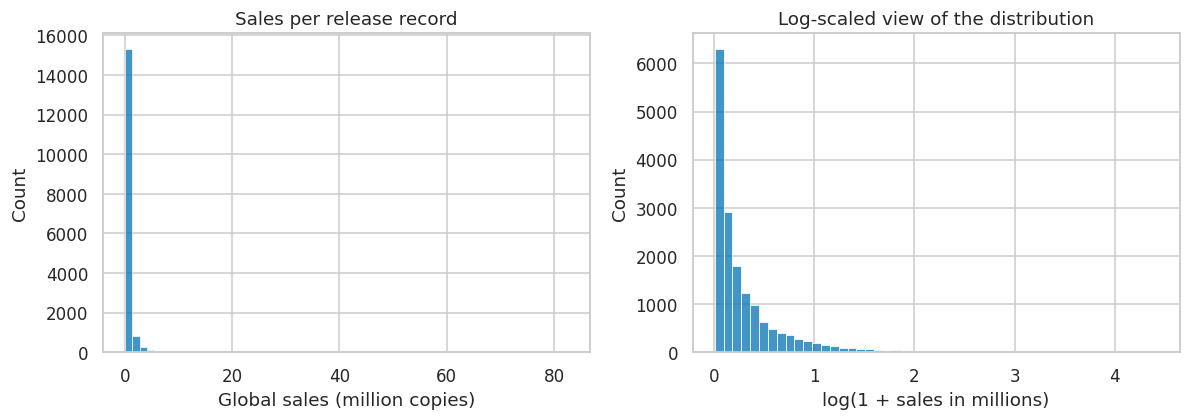

In [4]:
display(games[sales_cols + ['Critic_Score', 'User_Score']].describe().T)
valid_global = games['Global_Sales'].dropna().to_numpy()
print('Global sales quartiles (million copies):', np.quantile(valid_global, [0.25, 0.5, 0.75]))
print('Mean:', np.mean(valid_global), 'Median:', np.median(valid_global))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(games, x='Global_Sales', bins=60, ax=axes[0])
axes[0].set(title='Sales per release record', xlabel='Global sales (million copies)')
sns.histplot(np.log1p(valid_global), bins=50, ax=axes[1])
axes[1].set(title='Log-scaled view of the distribution', xlabel='log(1 + sales in millions)')
save_plot('01_sales_distribution.png')


## 4. Best-selling games, platforms, genres and publishers

,global_sales_m
Name,
Wii Sports,82.53
Grand Theft Auto V,56.57
Super Mario Bros.,45.31
Tetris,35.84
Mario Kart Wii,35.52
Wii Sports Resort,32.77
Pokemon Red/Pokemon Blue,31.37
Call of Duty: Black Ops,30.82
Call of Duty: Modern Warfare 3,30.59


,total,median,records
Platform,,,
PS2,1255.64,0.230,2161
X360,971.63,0.280,1262
PS3,939.43,0.270,1331
Wii,908.13,0.190,1320
DS,807.10,0.110,2152
PS,730.68,0.260,1197
GBA,318.50,0.165,822
PS4,314.23,0.200,393
PSP,294.30,0.090,1209


,total,median,mean,records
Genre,,,,
Action,1745.27,0.19,0.517884,3370
Sports,1332.00,0.22,0.567291,2348
Shooter,1052.94,0.23,0.795873,1323
Role-Playing,934.40,0.18,0.622933,1500
Platform,828.08,0.27,0.932523,888
Misc,803.18,0.16,0.458960,1750
Racing,728.90,0.19,0.583587,1249
Fighting,447.48,0.20,0.527067,849
Simulation,390.42,0.15,0.446705,874


,global_sales_m
Publisher,
Nintendo,1788.81
Electronic Arts,1116.96
Activision,731.16
Sony Computer Entertainment,606.48
Ubisoft,471.61
Take-Two Interactive,403.82
THQ,338.44
Konami Digital Entertainment,282.39
Sega,270.35


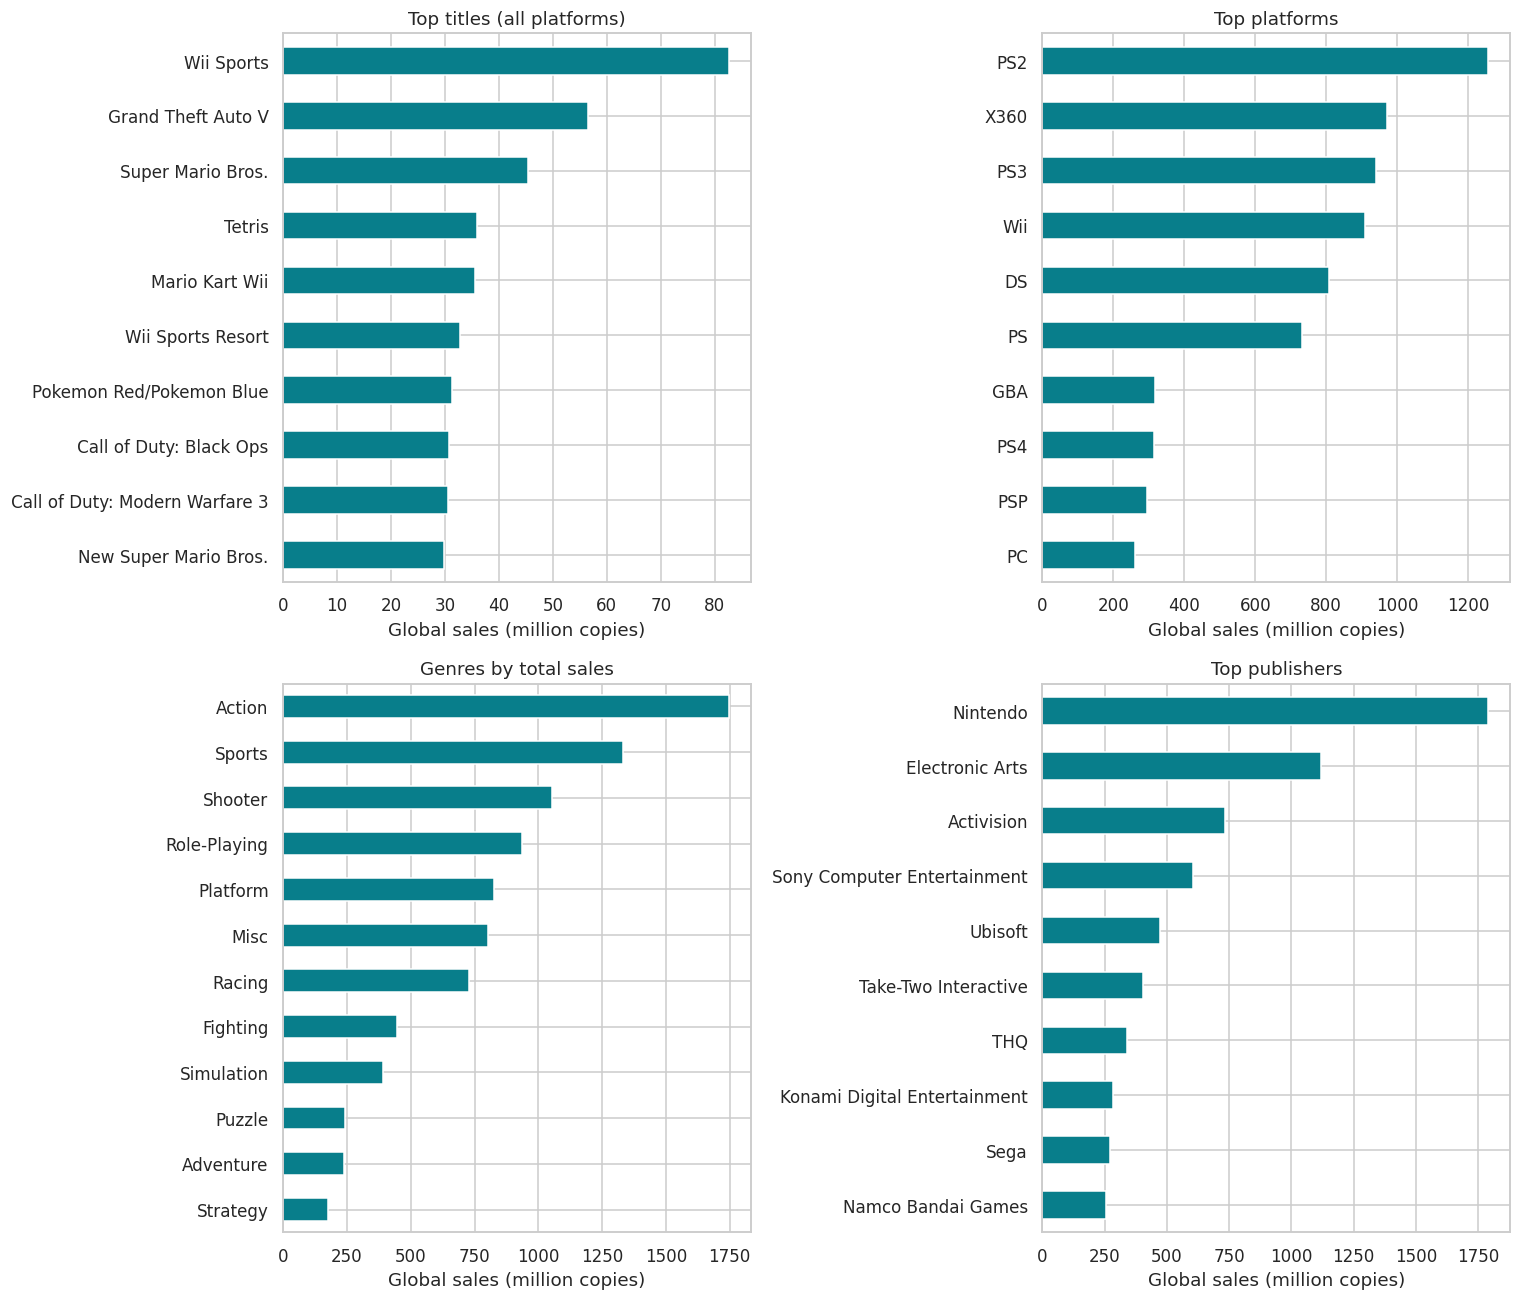

In [5]:
game_sales = games.groupby('Name')['Global_Sales'].sum(min_count=1).sort_values(ascending=False)
platform_sales = games.groupby('Platform')['Global_Sales'].agg(total='sum', median='median', records='count').sort_values('total', ascending=False)
genre_sales = games.groupby('Genre')['Global_Sales'].agg(total='sum', median='median', mean='mean', records='count').sort_values('total', ascending=False)
publisher_sales = games.groupby('Publisher')['Global_Sales'].sum(min_count=1).sort_values(ascending=False)
display(game_sales.head(10).to_frame('global_sales_m'))
display(platform_sales.head(10))
display(genre_sales)
display(publisher_sales.head(10).to_frame('global_sales_m'))
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, series, title in [(axes[0,0], game_sales.head(10), 'Top titles (all platforms)'),
                          (axes[0,1], platform_sales['total'].head(10), 'Top platforms'),
                          (axes[1,0], genre_sales['total'], 'Genres by total sales'),
                          (axes[1,1], publisher_sales.head(10), 'Top publishers')]:
    series.sort_values().plot.barh(ax=ax, color='#087e8b')
    ax.set(title=title, xlabel='Global sales (million copies)', ylabel='')
save_plot('02_leaders.png')


## 5. Regional preferences

,sales_m,share_of_regional_total_pct
NA_Sales,4400.84,49.371974
EU_Sales,2424.14,27.195848
JP_Sales,1297.40,14.555221
Other_Sales,791.26,8.876957


,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Platform,,,,
DS,NaN,NaN,175.57,NaN
PS,NaN,NaN,139.82,NaN
PS2,583.84,339.29,139.20,193.44
PS3,NaN,330.29,NaN,135.68
Wii,496.90,NaN,NaN,NaN
X360,602.47,270.76,NaN,85.76


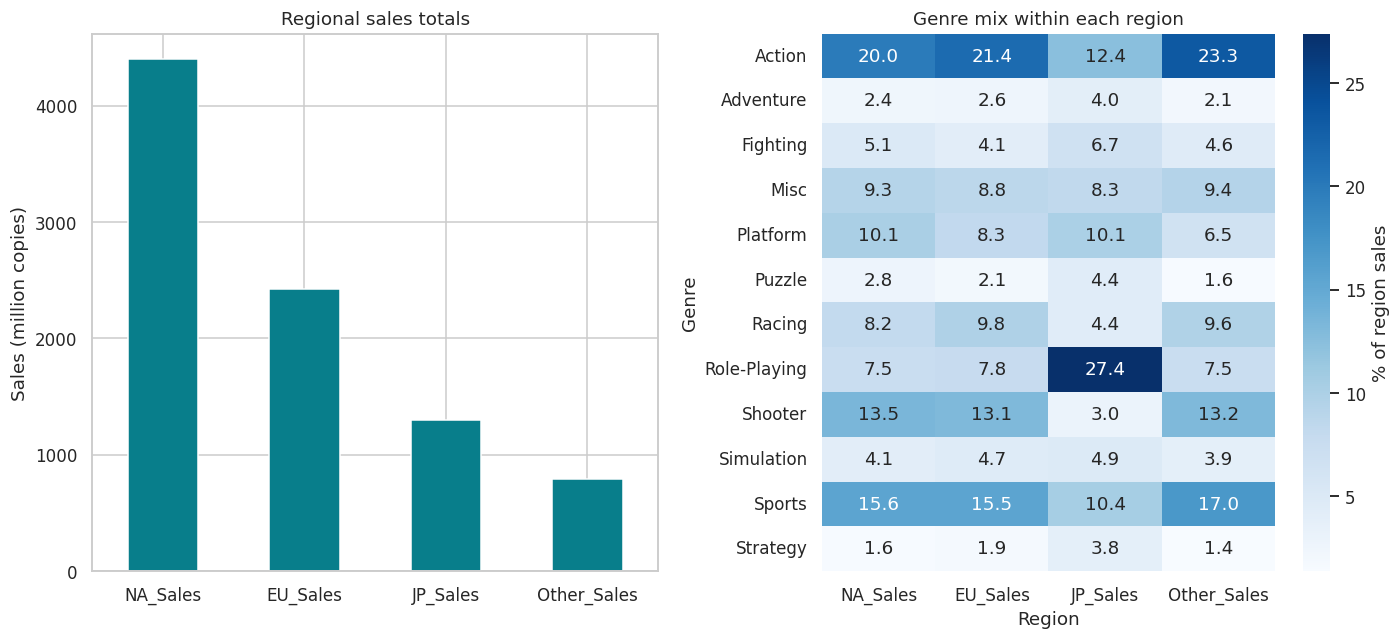

In [6]:
regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
region_totals = games[regions].sum()
region_share = region_totals / region_totals.sum() * 100
regional_genres = games.groupby('Genre')[regions].sum()
regional_preferences = regional_genres.div(regional_genres.sum(axis=0), axis=1) * 100
regional_leaders = pd.DataFrame({r: games.groupby('Platform')[r].sum().nlargest(3) for r in regions})
display(pd.DataFrame({'sales_m': region_totals, 'share_of_regional_total_pct': region_share}))
display(regional_leaders)
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
region_totals.plot.bar(ax=axes[0], rot=0, color='#087e8b', ylabel='Sales (million copies)', title='Regional sales totals')
sns.heatmap(regional_preferences, annot=True, fmt='.1f', cmap='Blues', ax=axes[1], cbar_kws={'label': '% of region sales'})
axes[1].set(title='Genre mix within each region', xlabel='Region', ylabel='Genre')
save_plot('03_regions.png')


## 6. Release-year trends

These are accumulated sales of release cohorts, not sales transactions occurring in each calendar year. Older releases have had more time to sell. The 2016 cohort is particularly incomplete at the snapshot date.

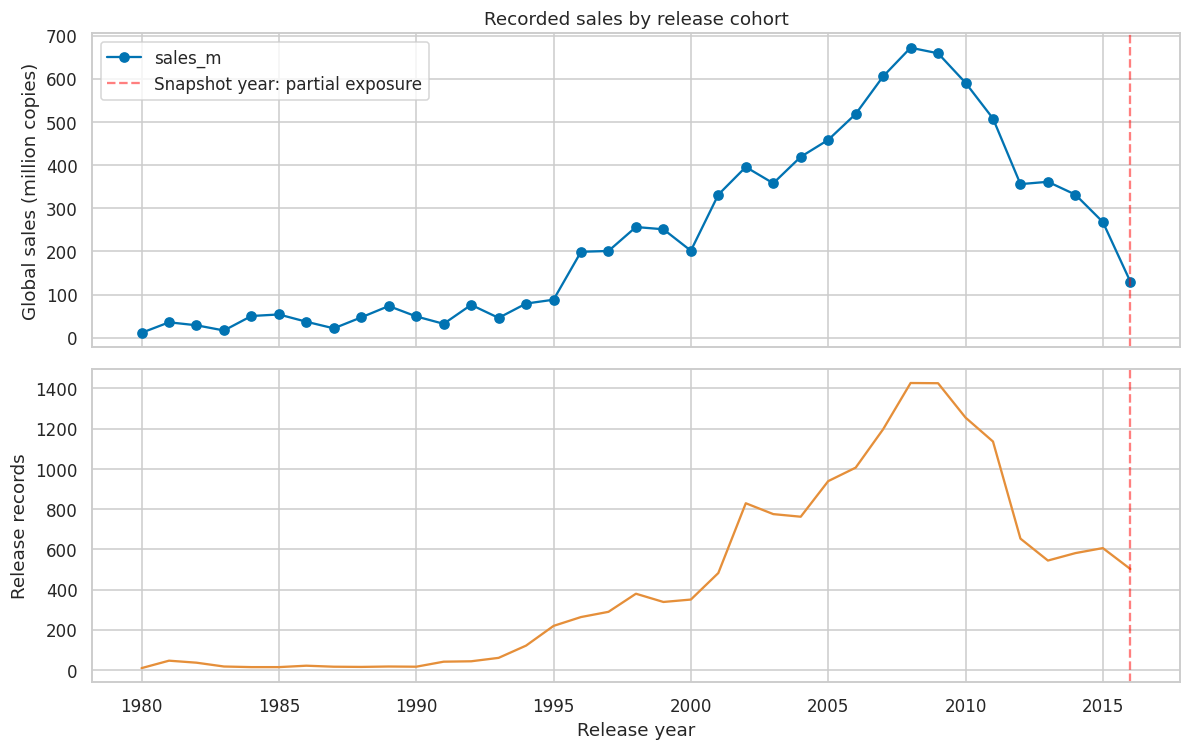

In [7]:
dated = games.dropna(subset=['Year_of_Release']).copy()
yearly = dated.groupby('Year_of_Release').agg(sales_m=('Global_Sales', 'sum'), release_records=('Name', 'size'))
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
yearly['sales_m'].plot(ax=axes[0], marker='o', ylabel='Global sales (million copies)', title='Recorded sales by release cohort')
yearly['release_records'].plot(ax=axes[1], color='#e58f3a', ylabel='Release records', xlabel='Release year')
for ax in axes: ax.axvline(2016, color='red', linestyle='--', alpha=0.5, label='Snapshot year: partial exposure')
axes[0].legend()
save_plot('04_release_trends.png')


## 7. Genre totals versus typical performance

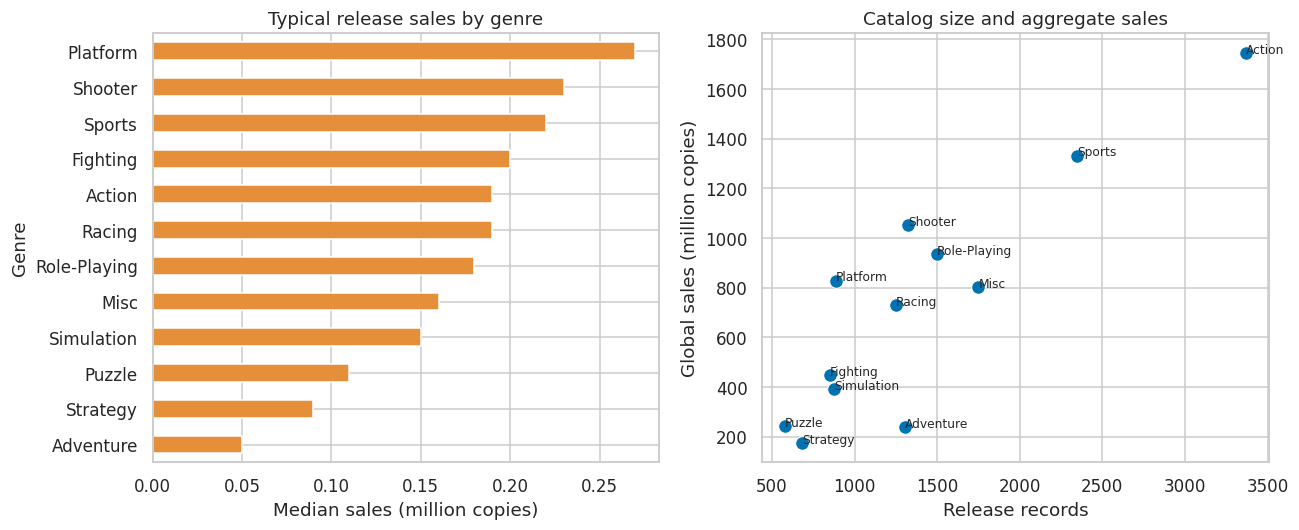

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
genre_sales['median'].sort_values().plot.barh(ax=axes[0], color='#e58f3a', xlabel='Median sales (million copies)', title='Typical release sales by genre')
sns.scatterplot(data=genre_sales.reset_index(), x='records', y='total', ax=axes[1], s=80)
for genre, row in genre_sales.iterrows():
    axes[1].annotate(genre, (row['records'], row['total']), fontsize=8)
axes[1].set(xlabel='Release records', ylabel='Global sales (million copies)', title='Catalog size and aggregate sales')
save_plot('05_genre_comparison.png')


## 8. Data checks and key findings

In [9]:
assert len(games) == len(raw) - exact_duplicates - missing_names
assert games['Name'].notna().all()
assert games['Year_of_Release'].dropna().between(1970, 2016).all()
assert not games[sales_cols].lt(0).any().any()
assert np.isclose(game_sales.sum(), games['Global_Sales'].sum())
assert np.isclose(region_share.sum(), 100)
known_sales = games['Global_Sales'].sum()
key_dedup = games.sort_values('Global_Sales', ascending=False).drop_duplicates(key)
sensitivity = float(known_sales - key_dedup['Global_Sales'].sum())
summary = {
 'raw_rows': len(raw), 'clean_rows': len(games), 'missing_names_removed': missing_names,
 'missing_name_sales_m': missing_name_sales, 'invalid_years': invalid_year_count,
 'unknown_years': int(games['Year_of_Release'].isna().sum()), 'key_duplicate_rows': len(key_duplicates),
 'duplicate_sensitivity_m': sensitivity, 'total_sales_m': float(known_sales),
 'median_release_sales_m': float(games['Global_Sales'].median()),
 'mean_release_sales_m': float(games['Global_Sales'].mean()),
 'top_game': str(game_sales.index[0]), 'top_game_sales_m': float(game_sales.iloc[0]),
 'top_platform': str(platform_sales.index[0]), 'top_platform_sales_m': float(platform_sales.iloc[0]['total']),
 'top_genre': str(genre_sales.index[0]), 'top_genre_sales_m': float(genre_sales.iloc[0]['total']),
 'highest_median_genre': str(genre_sales['median'].idxmax()),
 'highest_median_genre_sales_m': float(genre_sales['median'].max()),
 'top_publisher': str(publisher_sales.index[0]), 'top_publisher_sales_m': float(publisher_sales.iloc[0]),
 'top_region': str(region_totals.idxmax()), 'top_region_share_pct': float(region_share.max()),
 'japan_top_genre': str(regional_genres['JP_Sales'].idxmax()),
 'peak_cohort': int(yearly['sales_m'].idxmax()), 'peak_cohort_sales_m': float(yearly['sales_m'].max()),
 'top10_title_share_pct': float(game_sales.head(10).sum()/known_sales*100),
 'regional_sales_m': region_totals.to_dict()
}
(BASE / 'summary.json').write_text(json.dumps(summary, indent=2))
display(pd.Series(summary))
print(f"Largest title total: {summary['top_game']} ({summary['top_game_sales_m']:.2f} million copies).")
print(f"Top genre by total: {summary['top_genre']}; by median: {summary['highest_median_genre']}.")


Largest title total: Wii Sports (82.53 million copies).
Top genre by total: Action; by median: Platform.


raw_rows                                                                    16719
clean_rows                                                                  16717
missing_names_removed                                                           2
missing_name_sales_m                                                         2.42
invalid_years                                                                   4
unknown_years                                                                 273
key_duplicate_rows                                                              2
duplicate_sensitivity_m                                                      0.01
total_sales_m                                                             8917.88
median_release_sales_m                                                       0.17
mean_release_sales_m                                                     0.533462
top_game                                                               Wii Sports
top_game_sales_m

## 9. Business interpretation and limitations

- Assess catalog scale and median performance together: a genre with many releases can lead total sales without having the strongest typical release.
- Use region-specific genre mixes for historical market comparisons; Japan's pattern can differ from North America and Europe.
- Large publishers/platforms in this historical sample provide benchmarks, not forecasts of current success.
- Do not call sales totals profit or revenue. Cost, price, marketing spend, digital coverage and market representativeness are not established here.
- Two non-identical records share one known release key. They remain flagged; the summary quantifies the effect of keeping only the larger row. Title-name aggregation can also combine editions/remakes with the same name.
- Missing-year rows remain in other totals, but are excluded from time analysis. These descriptive patterns do not establish causality.

See `Report.pdf` for the concise findings from this exact run.